# Milestone 2: annotation checks and RGB baseline
Sarthak Jain · 23f3000839

The milestone requests RGB tensors scaled to [0,1] and exactly five training epochs. This notebook follows that configuration explicitly. The later final-model experiment uses a separate grayscale pipeline; its results are not substituted for this exercise.

In [1]:
from pathlib import Path
import json, random, time, platform
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import wandb

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(4)
ROOT = next(
    p.parent
    for p in Path("/kaggle/input").rglob("train.csv")
    if (p.parent / "train").is_dir()
)
OUT = Path("/kaggle/working")
OUT.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
H, W = 128, 800
raw = pd.read_csv(ROOT / "train.csv", keep_default_na=False)
raw.mask_rle = raw.mask_rle.str.strip()
table = (
    raw.pivot(index="image_id", columns="defect_type", values="mask_rle")
    .reindex(columns=CLASSES)
    .sort_index()
)


## Q1-Q6: RLE, prevalence, co-occurrence and pixel overlap
Co-occurrence counts are image-level counts. Pearson correlation is calculated over the binary per-image presence columns, so it adjusts for their base rates. Spatial overlap is checked separately on decoded native-resolution masks.

In [2]:
def decode(value):
    flat = np.zeros(H * W, np.uint8)
    if value.strip():
        a = np.asarray(value.split(), dtype=np.int64).reshape(-1, 2)
        for start, length in a:
            flat[start - 1 : start - 1 + length] = 1
    return flat.reshape(H, W, order="F")


presence = table.ne("").astype(int)
cooccur = presence.T @ presence
corr = presence.corr()
q1 = "12 2 23 4 44 2 47 1"
q2 = sum(int(decode(r).sum()) for r in table.loc["0ZUU8LH57Y"])
q3 = f"defect_c ({presence.defect_c.sum()}), defect_b ({presence.defect_b.sum()})"
pairs = [
    (int(cooccur.loc[a, b]), a, b)
    for i, a in enumerate(CLASSES)
    for b in CLASSES[i + 1 :]
]
count, a, b = max(pairs)
q4 = f"{a} and {b}, {count}"
q5 = f"{corr.loc[a,b]:.2f}, No"
maximum = 0
for image_id, row in table[presence.sum(axis=1) > 1].iterrows():
    masks = [decode(row[c]) for c in CLASSES if row[c]]
    for i, m in enumerate(masks):
        for other in masks[i + 1 :]:
            maximum = max(maximum, int((m & other).sum()))
q6 = f"{maximum}, " + ("Yes" if maximum == 0 else "No")
answers = {f"Q{i}": v for i, v in enumerate([q1, str(q2), q3, q4, q5, q6], 1)}
print(json.dumps(answers, indent=2))
display(cooccur)
display(corr.round(4))
cooccur.to_csv(OUT / "cooccurrence.csv")
corr.to_csv(OUT / "correlation.csv")
(OUT / "answers-q1-q6.json").write_text(json.dumps(answers, indent=2))


{
  "Q1": "12 2 23 4 44 2 47 1",
  "Q2": "6514",
  "Q3": "defect_c (4100), defect_b (313)",
  "Q4": "defect_c and defect_d, 705",
  "Q5": "0.05, No",
  "Q6": "0, Yes"
}


defect_type,defect_a,defect_b,defect_c,defect_d
defect_type,,,,
defect_a,1081,42,310,234
defect_b,42,313,95,64
defect_c,310,95,4100,705
defect_d,234,64,705,1707


defect_type,defect_a,defect_b,defect_c,defect_d
defect_type,,,,
defect_a,1.0000,0.0225,-0.0493,0.0605
defect_b,0.0225,1.0000,-0.0197,0.0257
defect_c,-0.0493,-0.0197,1.0000,0.0465
defect_d,0.0605,0.0257,0.0465,1.0000


168

## Q7: the requested RGB Dataset
One item contains one RGB strip and all four binary target channels. Both are float32 tensors. BCEWithLogitsLoss expects floating target values for its differentiable loss arithmetic; integer or boolean target tensors do not provide the required dtype.

In [3]:
class RGBSurfaceDataset(Dataset):
    def __init__(self, ids, augment=False):
        self.ids = list(ids)
        self.augment = augment

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        image_id = self.ids[i]
        with Image.open(ROOT / "train" / (image_id + ".jpg")) as f:
            image = np.asarray(f.convert("RGB"), np.float32) / 255
        mask = np.stack([decode(table.loc[image_id, c]) for c in CLASSES]).astype(
            "float32"
        )
        if self.augment:
            if random.random() < 0.5:
                image = image[:, ::-1]
                mask = mask[:, :, ::-1]
            if random.random() < 0.5:
                image = image[::-1]
                mask = mask[:, ::-1, :]
            if random.random() < 0.5:
                image = np.clip(
                    image * random.uniform(0.9, 1.1) + random.uniform(-0.05, 0.05), 0, 1
                )
        return torch.from_numpy(image.transpose(2, 0, 1).copy()), torch.from_numpy(
            mask.copy()
        )


combo = presence.apply(lambda r: "".join(str(v) for v in r), axis=1)
train_ids, val_ids = train_test_split(
    table.index.to_numpy(), test_size=0.2, stratify=combo, random_state=SEED
)
assert not set(train_ids) & set(val_ids)
images, masks = next(iter(DataLoader(RGBSurfaceDataset(train_ids), batch_size=4)))
assert images.shape == (4, 3, 128, 800) and masks.shape == (4, 4, 128, 800)
assert (
    images.dtype == masks.dtype == torch.float32
    and images.min() >= 0
    and images.max() <= 1
)
q7 = "(4, 3, 128, 800), (4, 4, 128, 800), torch.float32, BCEWithLogitsLoss requires floating targets for its loss arithmetic; integer or boolean masks cause a dtype error."
print(images.shape, masks.shape, images.dtype, masks.dtype)
print(q7)


torch.Size([4, 3, 128, 800]) torch.Size([4, 4, 128, 800]) torch.float32 torch.float32
(4, 3, 128, 800), (4, 4, 128, 800), torch.float32, BCEWithLogitsLoss requires floating targets for its loss arithmetic; integer or boolean masks cause a dtype error.


## Q8: five-epoch baseline
Use a small three-stage U-Net, AdamW at 3e-4 and the milestone BCE/positive-Dice loss. Keep the original seed-42 image split. Save the lowest validation-loss checkpoint and report the actual epoch 1 and epoch 5 losses. Augmentation affects training images and masks jointly; validation is unchanged.

wandb: Tracking run with wandb version 0.28.1
wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /kaggle/working/wandb/offline-run-20261029_153928-fw7y5ems
wandb: View this run in the terminal with `wandb leet`


{'epoch': 1, 'train_loss': 0.48438680770367365, 'val_loss': 0.40643141548483974, 'seconds': 87.49416974600001}
{'epoch': 2, 'train_loss': 0.40465682487961807, 'val_loss': 0.3905096479469666, 'seconds': 84.06087518099997}
{'epoch': 3, 'train_loss': 0.3855505725362726, 'val_loss': 0.3752138135908151, 'seconds': 83.95311095400001}
{'epoch': 4, 'train_loss': 0.36959785199463563, 'val_loss': 0.35374402453262277, 'seconds': 84.08670399499994}
{'epoch': 5, 'train_loss': 0.3572591178009639, 'val_loss': 0.35808526902096266, 'seconds': 83.74444999899993}


wandb: 
wandb: Run history:
wandb:      epoch ▁▃▅▆█
wandb:    seconds █▂▁▂▁
wandb: train_loss █▄▃▂▁
wandb:   val_loss █▆▄▁▂
wandb: 
wandb: Run summary:
wandb:    best_epoch 4
wandb: best_val_loss 0.35374
wandb:         epoch 5
wandb:       seconds 83.74445
wandb:    train_loss 0.35726
wandb:      val_loss 0.35809
wandb: 
wandb: You can sync this run to the cloud by running:
wandb: wandb sync /kaggle/working/wandb/offline-run-20261029_153928-fw7y5ems
wandb: Find logs at: ./wandb/offline-run-20261029_153928-fw7y5ems/logs


epoch1_(0.4844, 0.4064), epoch5_(0.3573, 0.3581), 4, Healthy generalization: training and validation loss both decreased over the five epochs, with no sustained validation-loss rise.


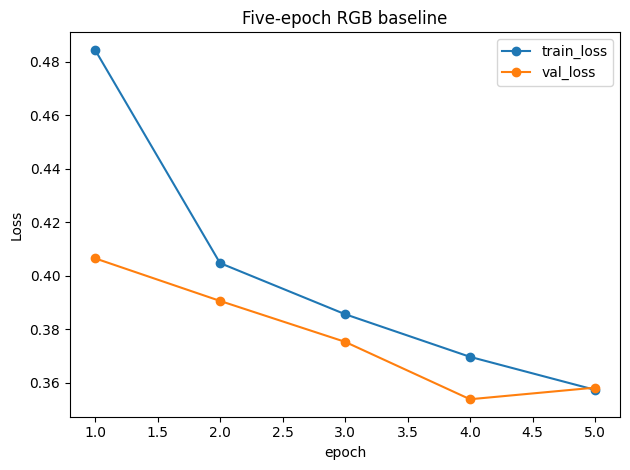

In [4]:
import torch
from torch import nn


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)
        self.bottleneck = ConvBlock(64, 128)
        self.pool = nn.MaxPool2d(2)
        self.dec3 = ConvBlock(128 + 64, 64)
        self.dec2 = ConvBlock(64 + 32, 32)
        self.dec1 = ConvBlock(32 + 16, 16)
        self.head = nn.Conv2d(16, 4, 1)

    def forward(self, x):
        a = self.enc1(x)
        b = self.enc2(self.pool(a))
        c = self.enc3(self.pool(b))
        x = self.bottleneck(self.pool(c))
        for skip, decoder in [(c, self.dec3), (b, self.dec2), (a, self.dec1)]:
            x = nn.functional.interpolate(
                x, size=skip.shape[-2:], mode="bilinear", align_corners=False
            )
            x = decoder(torch.cat([x, skip], dim=1))
        return self.head(x)


def criterion(logits, targets):
    logits = logits.float()
    p = logits.sigmoid()
    inter = (p * targets).sum((-2, -1))
    den = (p + targets).sum((-2, -1))
    positive = targets.sum((-2, -1)) > 0
    dice = 1 - (2 * inter + 1e-6) / (den + 1e-6)
    return 0.5 * nn.functional.binary_cross_entropy_with_logits(
        logits, targets
    ) + 0.5 * (dice * positive).sum() / positive.sum().clamp_min(1)


model = SmallUNet().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
kwargs = dict(batch_size=16, num_workers=2, pin_memory=DEVICE.type == "cuda")
train_loader = DataLoader(
    RGBSurfaceDataset(train_ids, True),
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    **kwargs,
)
val_loader = DataLoader(RGBSurfaceDataset(val_ids), shuffle=False, **kwargs)
run = wandb.init(
    entity="23f3000839-iit-madras-foundation",
    project="23f3000839-t32026",
    name="milestone2-rgb-unet-five-epochs",
    mode="offline",
    dir=str(OUT),
    config={
        "architecture": "small_unet_rgb",
        "input_channels": 3,
        "normalization": "divide by 255",
        "epochs": 5,
        "lr": 3e-4,
        "seed": SEED,
        "train_images": len(train_ids),
        "validation_images": len(val_ids),
        "augmentation": "flips brightness contrast",
    },
)
history = []
best = float("inf")
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
for epoch in range(1, 6):
    model.train()
    total = 0.0
    n = 0
    start = time.perf_counter()
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item() * len(x)
        n += len(x)
    train_loss = total / n
    model.eval()
    total = 0.0
    n = 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = criterion(model(x), y)
            total += loss.item() * len(x)
            n += len(x)
    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": total / n,
        "seconds": time.perf_counter() - start,
    }
    history.append(row)
    run.log(row)
    print(row, flush=True)
    pd.DataFrame(history).to_csv(OUT / "history.csv", index=False)
    if row["val_loss"] < best:
        best = row["val_loss"]
        torch.save(model.state_dict(), OUT / "m2-rgb-unet.pt")
h = pd.DataFrame(history)
best_epoch = int(h.loc[h.val_loss.idxmin(), "epoch"])
run.summary.update({"best_epoch": best_epoch, "best_val_loss": best})
run.finish()
a, b = history[0], history[-1]
assessment = (
    "Healthy generalization: training and validation loss both decreased over the five epochs, with no sustained validation-loss rise."
    if b["val_loss"] < a["val_loss"] and best_epoch >= 4
    else "The curves require caution: the minimum validation loss occurred before the final epoch, so later training did not consistently improve held-out performance."
)
q8 = f"epoch1_({a['train_loss']:.4f}, {a['val_loss']:.4f}), epoch5_({b['train_loss']:.4f}, {b['val_loss']:.4f}), {best_epoch}, {assessment}"
answers["Q7"] = q7
answers["Q8"] = q8
(OUT / "answers.json").write_text(json.dumps(answers, indent=2))
print(q8)
h.plot(
    x="epoch", y=["train_loss", "val_loss"], marker="o", title="Five-epoch RGB baseline"
)
plt.ylabel("Loss")
plt.tight_layout()
plt.savefig(OUT / "loss_curves.png", dpi=150)
plt.show()
